In [14]:
import sys
import time
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from scipy import ndimage

# walk up the folders until finding the repo (where the config and the data are)
ROOT = next(p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents]
            if (p / "common" / "config.py").is_file())
sys.path.insert(0, str(ROOT))

from common import config, milk10k      # data only: image paths, metadata, leak-free splits

np.set_printoptions(precision=2, suppress=True)

In [15]:
toy = np.array([
    [100, 100, 100, 100, 100],
    [100, 100, 100, 100, 100],
    [100, 100,  10,  10,  10],
    [100, 100,  10,  10,  10],
    [100, 100,  10,  10,  10],
], dtype=float)                         # 100 = skin, 10 = lesion
toy

array([[100., 100., 100., 100., 100.],
       [100., 100., 100., 100., 100.],
       [100., 100.,  10.,  10.,  10.],
       [100., 100.,  10.,  10.,  10.],
       [100., 100.,  10.,  10.,  10.]])

In [16]:
# 1a. Histogram: how many pixels fall in each intensity bin
counts, edges = np.histogram(toy, bins=4, range=(0, 256))
print(counts)                           # [ 9 16  0  0]
print(counts / toy.size) 

[ 9 16  0  0]
[0.36 0.64 0.   0.  ]


In [17]:
# 1b. Mean and std
print(toy.mean())                                   # 67.6
print(toy.std())                                    # 43.2
print(np.sqrt((toy**2).mean() - toy.mean()**2))     # 43.2 again: mean(x²) - mean(x)²

67.6
43.2
43.20000000000001


[[ 10.  10. 100.  10. 100.]
 [ 10. 100.  10. 100. 100.]
 [ 10. 100. 100. 100. 100.]
 [100. 100. 100.  10. 100.]
 [100. 100. 100.  10.  10.]]
[ 9 16  0  0] 67.6 43.2


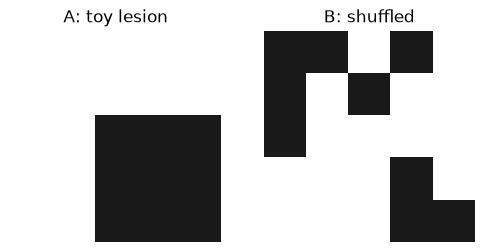

In [18]:
# 1c. Same pixels, shuffled -> same histogram, mean and std
rng = np.random.default_rng(3)
shuffled = rng.permutation(toy.ravel()).reshape(5, 5)
print(shuffled)
print(np.histogram(shuffled, bins=4, range=(0, 256))[0], shuffled.mean(), shuffled.std())

fig, axes = plt.subplots(1, 2, figsize=(6, 3))
axes[0].imshow(toy, cmap="gray", vmin=0, vmax=100);      axes[0].set_title("A: toy lesion")
axes[1].imshow(shuffled, cmap="gray", vmin=0, vmax=100); axes[1].set_title("B: shuffled")
for ax in axes:
    ax.axis("off")

The simplest texture measure: how often a pixel differs from its right neighbor. 
`img[:, 1:]` is every column except the first, 
`img[:, :-1]` every column except the last: side by side, they compare each pixel with its right neighbor. 
`!=` gives True/False, 
`.sum()` counts the Trues.

In [19]:
# 1d. Texture: count left -> right changes between neighbors
def n_changes(img):
    return (img[:, 1:] != img[:, :-1]).sum()    # each pixel vs its right neighbor

print(n_changes(toy), n_changes(shuffled))        # 3 10

3 10


In [20]:
# 1e. Edge density: mean Sobel magnitude (Session 4)
gx = ndimage.sobel(toy, axis=1)         # change left -> right
gy = ndimage.sobel(toy, axis=0)         # change top -> bottom
magnitude = np.hypot(gx, gy)            # sqrt(gx**2 + gy**2)
print(magnitude[1:-1, 1:-1])            # 3x3 'valid' part = Session 4's slide
print(magnitude[1:-1, 1:-1].mean())     # 279.8 -> edge density

[[127.28 284.6  360.  ]
 [284.6  381.84 360.  ]
 [360.   360.     0.  ]]
279.81409569829134


In [21]:
def texture_features(rgb):
    """3 numbers: edge density, roughness, Laplacian variance (on grayscale)."""
    gray = rgb.mean(axis=2)                                   # simple grayscale

    # 1. edge density: mean Sobel magnitude (Session 4)
    gx, gy = ndimage.sobel(gray, axis=1), ndimage.sobel(gray, axis=0)
    edge_density = np.hypot(gx, gy).mean()

    # 2. roughness: mean local variance in 9x9 windows, mean(x²) - mean(x)²
    local_mean = ndimage.uniform_filter(gray, size=9)         # box blur
    local_sq_mean = ndimage.uniform_filter(gray**2, size=9)
    roughness = (local_sq_mean - local_mean**2).mean()

    # 3. sharpness: variance of the Laplacian (2nd derivative)
    laplacian_var = ndimage.laplace(gray).var()

    return np.array([edge_density, roughness, laplacian_var])               # [ 25.9  58.5 105.4]